# 7CS537 CW2, Notebook 05: Autoencoder anomaly detector

**Student number:** 100810453

**Purpose:** build the second layer of the CW2 triage system, an autoencoder that learns only what normal TeleComNet traffic looks like, and test whether it flags the new attack families that XGBoost missed in Notebook 04.

**Why:** Notebook 04 showed that XGBoost, trained on earlier days, detected 0.12% of Friday's attacks and 0.05% of Wednesday's. A supervised model can only recognise attacks it was shown. An anomaly detector needs no attack examples: it raises an alert when traffic does not look normal. The question this notebook answers is whether that adds useful detection without an impractical number of false alarms.

**How an autoencoder works:** it is a small neural network trained to copy its input to its output through a narrow middle layer (here 8 numbers for 62 features). To do that it has to learn the typical relationships between features in normal traffic. When it is given a flow unlike anything in training, it copies it badly. The size of that copying error (the reconstruction error) is the anomaly score. This approach was used for network intrusion detection by Kitsune (Mirsky et al., 2018).

**Comparison model:** Isolation Forest, as in CW1, trained on the same benign Monday flows and given the same threshold rule, so the comparison is fair.

**Experiments:**
- **Time-ordered:** both detectors trained on benign Monday traffic, tested on Tuesday, Wednesday, Thursday and Friday (Friday = E1, the main result).
- **E3, held-out attack family:** in Notebook 05b, which uses the scores saved here. It is a separate notebook because retraining XGBoost in the same Python process as PyTorch crashed on macOS (both libraries load their own copy of the OpenMP threading library).

**Inputs:** CW1 data and feature list; `cw2/data/03_splits.parquet`; `cw2/data/04_xgb_test_scores.parquet`; Notebook 03 and 04 outputs.

**Outputs:** `cw2/outputs/05_*`, `cw2/models/05_*` (autoencoder, preprocessing, Isolation Forest), `cw2/data/05_anomaly_scores.parquet` (scores for Notebook 06).

**Before running:** install PyTorch in the project environment (`pip install torch`). Run from Terminal in the repository folder: `jupyter nbconvert --to notebook --execute --inplace cw2/05_autoencoder.ipynb`.

## 1. Setup and configuration
**What:** imports, paths and every setting in one place.

**Why each setting:**
- `TARGET_FPR = 0.01`: the alert threshold is set so that about 1% of benign flows in the calibration period would be flagged. This is a SOC workload decision, made before testing and without attack labels, not a value tuned for the best score.
- Network shape 62, 32, 16, 8, 16, 32, 62: wide enough to learn normal traffic, narrow enough in the middle that it cannot simply copy every input.
- Adam optimiser, learning rate 0.001, batches of 1,024 flows: standard, stable defaults for a small network.
- Up to 50 passes over the data (epochs), stopping when validation loss has not improved for 3 epochs, and keeping the best version. This stops the model over-fitting Monday's traffic.
- The model is trained on the CPU with fixed seeds, so a re-run gives the same model.
- PyTorch is imported first, and XGBoost is not imported at all, to avoid a library clash that crashes Python on macOS (see the comment in the code). XGBoost results from Notebook 04 are read from its saved scores instead.

In [1]:
# PyTorch must be imported BEFORE scikit-learn. On macOS each library ships its own copy of the OpenMP
# threading library; loading scikit-learn or XGBoost first made Python crash (segmentation fault) when
# PyTorch was loaded afterwards. XGBoost is not used in this notebook for the same reason (see Notebook 05b).
import torch
from torch import nn

import os
import json
import time
import hashlib
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import joblib
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, matthews_corrcoef)

try:
    from IPython.display import display
except ImportError:
    display = print

RANDOM_STATE = 42
TARGET_FPR = 0.01
HIDDEN = [32, 16, 8]
LEARNING_RATE = 1e-3
BATCH_SIZE = 1024
MAX_EPOCHS = 50
PATIENCE = 3
CLIP = 10.0                 # scaled values are clipped to +/-10 so a few extreme flows cannot dominate training
IF_PARAMS = dict(n_estimators=200, max_samples=256, random_state=RANDOM_STATE, n_jobs=-1)   # as CW1
DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
TEST_DAYS = ["Tuesday", "Wednesday", "Thursday", "Friday"]

torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
device = torch.device("cpu")

ROOT = ".." if os.path.exists(os.path.join("..", "outputs", "01_feature_list.txt")) else "."
DATA_FILE = os.path.join(ROOT, "data", "cicids2017_clean.parquet")
CW1_OUT = os.path.join(ROOT, "outputs")
CW2_DIR = os.path.join(ROOT, "cw2")
OUT_DIR = os.path.join(CW2_DIR, "outputs")
MODEL_DIR = os.path.join(CW2_DIR, "models")
SPLIT_FILE = os.path.join(CW2_DIR, "data", "03_splits.parquet")
XGB_SCORE_FILE = os.path.join(CW2_DIR, "data", "04_xgb_test_scores.parquet")
SCORE_FILE = os.path.join(CW2_DIR, "data", "05_anomaly_scores.parquet")
os.makedirs(MODEL_DIR, exist_ok=True)

print("torch", torch.__version__, "| scikit-learn", sklearn.__version__, "| numpy", np.__version__)

torch 2.15.0 | scikit-learn 1.9.1 | numpy 2.5.4


## 2. Load the data and the Notebook 03 splits
**What and why:** as in Notebook 04, the data fingerprint is checked so the split file refers to the same flows.

In [2]:
if os.path.exists(DATA_FILE):
    df = pd.read_parquet(DATA_FILE)
else:
    df = pd.read_pickle(DATA_FILE.replace(".parquet", ".pkl"))
for col in ["Label", "attack_family", "source_file"]:
    df[col] = df[col].astype(str)
with open(os.path.join(CW1_OUT, "01_feature_list.txt")) as fh:
    feature_cols = [line.strip() for line in fh if line.strip()]
with open(os.path.join(OUT_DIR, "03_run_config.json")) as fh:
    nb03_config = json.load(fh)
h = pd.util.hash_pandas_object(df[["Label", "source_file"]], index=False).to_numpy()
fingerprint = hashlib.sha256(h.tobytes()).hexdigest()[:16]
assert fingerprint == nb03_config["data_fingerprint"], "Data differs from Notebook 03; re-run Notebook 03"

splits = pd.read_parquet(SPLIT_FILE)
splits["day"] = splits["day"].astype(str)
X_raw = df[feature_cols].to_numpy(dtype=np.float32)   # float32 as in CW1, to save memory
y_all = df["is_attack"].to_numpy().astype(int)
labels = df["Label"].to_numpy()
families = df["attack_family"].to_numpy()
day = splits["day"].to_numpy()
ae_role = splits["ae_role"].astype(str).to_numpy()
ae_train_idx = np.where(ae_role == "ae_train")[0]
ae_val_idx = np.where(ae_role == "ae_val")[0]
print(f"{len(df):,} flows. Autoencoder training {len(ae_train_idx):,}, early stopping {len(ae_val_idx):,}.")

2,496,544 flows. Autoencoder training 394,060, early stopping 98,516.


## 3. Preprocessing for the autoencoder
**What:**
1. A signed log transform, `sign(x) * log(1 + |x|)`, applied to every feature.
2. Standard scaling (mean 0, standard deviation 1) using means and standard deviations learnt from the **autoencoder training flows only**.
3. Clipping to the range -10 to +10.

**Why:**
- Flow features are extremely skewed: durations and byte rates range from 0 to many millions. Without the log, a handful of huge values would dominate the reconstruction error, and every large but normal flow would look anomalous. The signed version keeps the few negative values (for example a TCP window of -1) usable.
- A neural network trains reliably only when inputs are on similar scales. Fitting the scaler on training flows only means no information from later days leaks into the model.
- After scaling, each feature's error is measured in standard deviations of normal traffic, so per-feature errors are comparable. Notebook 06 relies on this to explain alerts.
- Clipping stops a single extreme value from producing an error so large that it hides everything else. Clipped values still give a large error, so such flows are still flagged.

Isolation Forest uses the raw features, as in CW1. Its splits do not depend on the scale of a feature, so scaling would not change it.

In [3]:
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))

scaler = StandardScaler().fit(signed_log(X_raw[ae_train_idx]))

def preprocess(x):
    return np.clip(scaler.transform(signed_log(x)), -CLIP, CLIP).astype(np.float32)

X_all = preprocess(X_raw)
print("Share of values clipped across all flows: "
      f"{100 * np.mean(np.abs(X_all) >= CLIP):.4f}%")
joblib.dump({"scaler": scaler, "clip": CLIP, "feature_cols": feature_cols}, os.path.join(MODEL_DIR, "05_preprocess.joblib"))

Share of values clipped across all flows: 0.0022%


['../cw2/models/05_preprocess.joblib']

**What this shows:** only 0.0022% of all values were clipped, so clipping affects a tiny number of extreme flows and does not change the data in general.

## 4. Define and train the autoencoder
**What:** defines the network and trains it with an explicit loop. Each epoch: shuffle the training flows, and for each batch run the flows through the network (forward pass), measure the mean squared reconstruction error (loss), work out how each weight affected the loss (backpropagation) and adjust the weights a little (optimiser step). After each epoch the loss on the 20% Monday hold-out is measured; training stops when it has not improved for 3 epochs, and the best weights are restored.

**Why an explicit loop:** every step of training is visible and can be explained, which matters more for this coursework than saving a few lines of code.

Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=62, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=8, bias=True)
    (5): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=8, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=62, bias=True)
  )
)
Trainable weights: 5414


epoch  1: train 0.35132, validation 0.13348


epoch  2: train 0.09867, validation 0.06604


epoch  3: train 0.06272, validation 0.05106


epoch  4: train 0.05121, validation 0.04343


epoch  5: train 0.04489, validation 0.03917


... (41 outputs left out)

epoch 47: train 0.02202, validation 0.02030


epoch 48: train 0.02197, validation 0.02018


epoch 49: train 0.02185, validation 0.02010


epoch 50: train 0.02182, validation 0.02010
Best epoch 49, validation loss 0.02010, training time 14 s


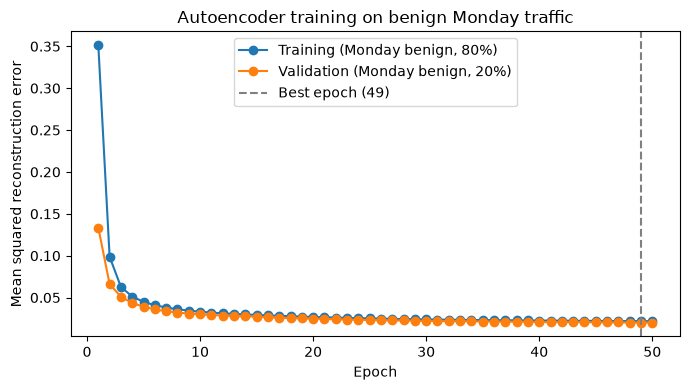

In [4]:
class Autoencoder(nn.Module):
    def __init__(self, n_features, hidden):
        super().__init__()
        enc, dec, size = [], [], n_features
        for width in hidden:                       # encoder: 62 -> 32 -> 16 -> 8
            enc += [nn.Linear(size, width), nn.ReLU()]
            size = width
        for width in reversed(hidden[:-1]):        # decoder: 8 -> 16 -> 32
            dec += [nn.Linear(size, width), nn.ReLU()]
            size = width
        dec += [nn.Linear(size, n_features)]       # output: 32 -> 62, no activation
        self.encoder, self.decoder = nn.Sequential(*enc), nn.Sequential(*dec)

    def forward(self, x):
        return self.decoder(self.encoder(x))

model = Autoencoder(len(feature_cols), HIDDEN).to(device)
optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
loss_fn = nn.MSELoss()
print(model)
print("Trainable weights:", sum(p.numel() for p in model.parameters()))

X_tr = torch.from_numpy(X_all[ae_train_idx])
X_va = torch.from_numpy(X_all[ae_val_idx])
gen = torch.Generator().manual_seed(RANDOM_STATE)

def mean_loss(x):
    model.eval()
    with torch.no_grad():
        return float(np.mean([loss_fn(model(b), b).item() for b in torch.split(x, 65536)]))

history, best_val, best_state, waited = [], np.inf, None, 0
t0 = time.time()
for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    order = torch.randperm(len(X_tr), generator=gen)
    batch_losses = []
    for start in range(0, len(order), BATCH_SIZE):
        batch = X_tr[order[start:start + BATCH_SIZE]]
        optimiser.zero_grad()
        loss = loss_fn(model(batch), batch)       # forward pass and reconstruction error
        loss.backward()                           # backpropagation
        optimiser.step()                          # adjust the weights
        batch_losses.append(loss.item())
    val_loss = mean_loss(X_va)
    history.append({"epoch": epoch, "train_loss": np.mean(batch_losses), "val_loss": val_loss})
    print(f"epoch {epoch:2d}: train {history[-1]['train_loss']:.5f}, validation {val_loss:.5f}")
    if val_loss < best_val - 1e-6:
        best_val, waited = val_loss, 0
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    else:
        waited += 1
        if waited >= PATIENCE:
            print(f"Stopped: no improvement for {PATIENCE} epochs.")
            break
model.load_state_dict(best_state)
ae_fit_s = time.time() - t0
best_epoch = int(pd.DataFrame(history)["val_loss"].idxmin() + 1)
print(f"Best epoch {best_epoch}, validation loss {best_val:.5f}, training time {ae_fit_s:.0f} s")
torch.save(model.state_dict(), os.path.join(MODEL_DIR, "05_autoencoder.pt"))
pd.DataFrame(history).to_csv(f"{OUT_DIR}/05_ae_training_history.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
hist = pd.DataFrame(history)
ax.plot(hist["epoch"], hist["train_loss"], marker="o", label="Training (Monday benign, 80%)")
ax.plot(hist["epoch"], hist["val_loss"], marker="o", label="Validation (Monday benign, 20%)")
ax.axvline(best_epoch, color="grey", linestyle="--", label=f"Best epoch ({best_epoch})")
ax.set_xlabel("Epoch"); ax.set_ylabel("Mean squared reconstruction error")
ax.set_title("Autoencoder training on benign Monday traffic")
ax.legend(); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/05_ae_training_loss.png", dpi=200); plt.show()

**What this shows** (`05_ae_training_history.csv`, `05_ae_training_loss.png`): the loss fell quickly from 0.351 (training) and 0.133 (validation) in the first epoch to 0.0218 and 0.0201 by epoch 50, and training took about 14 seconds. Validation loss never rose, so there is no sign of over-fitting.

Validation loss is slightly lower than training loss throughout. This is expected: the training figure is an average over an epoch while the weights are still improving, whereas validation is measured at the end of the epoch.

**Limitation:** the best epoch was 49 of a maximum of 50, so training ended at the epoch limit, not by early stopping. The improvement had become very small (0.02018 to 0.02010 over the last two epochs, under 0.5%), so more epochs would probably change the results only slightly, but this has not been tested.

## 5. Anomaly scores for every flow
**What:** computes the autoencoder's reconstruction error for every flow, and trains Isolation Forest on the same benign Monday flows and scores every flow.

**Why every flow:** Notebook 06 combines these scores with XGBoost's, so they are saved once here. Flows used to train a model are marked in the split file and are never used to measure that model's performance.

In [5]:
def reconstruction_error(x, batch=65536):
    model.eval()
    out = []
    with torch.no_grad():
        for b in torch.split(torch.from_numpy(x), batch):
            out.append(((model(b) - b) ** 2).mean(dim=1).numpy())
    return np.concatenate(out)

t0 = time.time()
ae_score = reconstruction_error(X_all)
ae_score_s = time.time() - t0

t0 = time.time()
iso = IsolationForest(**IF_PARAMS).fit(X_raw[ae_train_idx])
if_fit_s = time.time() - t0
if_score = -iso.score_samples(X_raw)      # higher = more anomalous
joblib.dump(iso, os.path.join(MODEL_DIR, "05_isolation_forest.joblib"))

pd.DataFrame({"row_id": np.arange(len(df)), "ae_error": ae_score, "if_score": if_score}).to_parquet(SCORE_FILE, index=False)
print(f"Autoencoder scored all flows in {ae_score_s:.0f} s; Isolation Forest trained in {if_fit_s:.0f} s.")

Autoencoder scored all flows in 0 s; Isolation Forest trained in 0 s.


## 6. Alert thresholds from benign traffic only
**What:** for each test day, the threshold is the 99th percentile (1 - `TARGET_FPR`) of scores on a **calibration set of benign flows from before that day**: the 20% Monday hold-out plus every benign flow from Tuesday up to the day before the test day. This is the rule fixed in Notebook 03.

**Why:**
- Attack labels are never used, unlike CW1's Isolation Forest threshold, which was chosen for the best F1 on validation data that included attacks. In a real SOC, the attacks to come are unknown, so a threshold tuned on them would be unrealistic.
- The test day is never used, so the false positive rate on the test day is an honest measure.
- Using recent benign days, not just Monday, lets the threshold follow normal changes in traffic over the week. The difference between the 1% target and the false positive rate actually seen on the test day measures how much normal traffic drifts from one day to the next.

In [6]:
def calibration_rows(test_day):
    before = DAY_ORDER[1:DAY_ORDER.index(test_day)]
    return np.where((ae_role == "ae_val") | (np.isin(day, before) & (y_all == 0)))[0]

thresholds = {}
for d in TEST_DAYS:
    cal = calibration_rows(d)
    thresholds[d] = {"calibration_flows": len(cal),
                     "ae": float(np.quantile(ae_score[cal], 1 - TARGET_FPR)),
                     "if": float(np.quantile(if_score[cal], 1 - TARGET_FPR))}
thr = pd.DataFrame(thresholds).T
thr.to_csv(f"{OUT_DIR}/05_thresholds.csv")
display(thr)

,calibration_flows,ae,if
Tuesday,98516.0,0.220626,0.634821
Wednesday,495808.0,0.359063,0.634453
Thursday,888627.0,0.368901,0.650965
Friday,1282732.0,0.343633,0.644692


**What this shows** (`05_thresholds.csv`): the autoencoder threshold for Tuesday, calibrated on the Monday hold-out only, is 0.221. Once benign Tuesday to Thursday traffic is added to the calibration set, it rises to between 0.34 and 0.37. So normal traffic later in the week contains more unusual-looking flows than Monday's. A threshold set only on Monday would have raised far more false alarms later in the week; Section 7 shows how much drift remains even with this rule.

## 7. Time-ordered results: autoencoder, Isolation Forest and XGBoost
**What:** for each test day, the same metrics as Notebook 04 for the autoencoder and Isolation Forest, with XGBoost's results from Notebook 04 alongside (Wednesday to Friday; Tuesday has no XGBoost result because there were no earlier attacks to train on).

**What to look for:** detection rate and missed attacks against false alarms. The false positive rate on the test day should be compared with the 1% target: a much higher figure means that day's normal traffic differs from the calibration days.

In [7]:
def evaluate(model_name, test_day, y_true, score, threshold):
    y_pred = (score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"model": model_name, "test_day": test_day, "threshold": threshold,
            "detection_rate": recall_score(y_true, y_pred, zero_division=0),
            "fpr": fp / (fp + tn), "precision": precision_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0), "mcc": matthews_corrcoef(y_true, y_pred),
            "roc_auc": roc_auc_score(y_true, score), "pr_auc": average_precision_score(y_true, score),
            "TP": int(tp), "FN_missed_attacks": int(fn), "FP_false_alarms": int(fp), "TN": int(tn)}

xgb_scores = pd.read_parquet(XGB_SCORE_FILE)
xgb_col = {"Wednesday": "E2_Wednesday", "Thursday": "E2_Thursday", "Friday": "E1"}
rows, label_rows = [], []
for d in TEST_DAYS:
    te = np.where(day == d)[0]
    entries = [("Autoencoder", ae_score[te], thresholds[d]["ae"]),
               ("Isolation Forest", if_score[te], thresholds[d]["if"])]
    if d in xgb_col:
        entries.append(("XGBoost (Notebook 04)", xgb_scores[xgb_col[d]].to_numpy()[te], 0.5))
    for name, s, t in entries:
        rows.append(evaluate(name, d, y_all[te], s, t))
        flagged = pd.DataFrame({"Label": labels[te], "flagged": s >= t})
        g = flagged.groupby("Label").agg(test_flows=("flagged", "size"), flagged=("flagged", "sum"))
        g["flagged_pct"] = 100 * g["flagged"] / g["test_flows"]
        g["model"], g["test_day"] = name, d
        label_rows.append(g.reset_index())

time_res = pd.DataFrame(rows)
time_res.to_csv(f"{OUT_DIR}/05_time_ordered_results.csv", index=False)
time_labels = pd.concat(label_rows, ignore_index=True)
time_labels.to_csv(f"{OUT_DIR}/05_time_ordered_by_label.csv", index=False)
display(time_res[["test_day", "model", "detection_rate", "fpr", "precision", "mcc", "pr_auc",
                  "TP", "FN_missed_attacks", "FP_false_alarms"]].round(4))

,test_day,model,detection_rate,fpr,precision,mcc,pr_auc,TP,FN_missed_attacks,FP_false_alarms
0,Tuesday,Autoencoder,0.0019,0.0248,0.0017,-0.0221,0.0438,17,9133,9851
1,Tuesday,Isolation Forest,0.0000,0.0098,0.0000,-0.0149,0.0382,0,9150,3891
2,Wednesday,Autoencoder,0.7837,0.0120,0.9698,0.8205,0.9405,151725,41865,4725
3,Wednesday,Isolation Forest,0.7078,0.0201,0.9455,0.7497,0.8304,137016,56574,7903
4,Wednesday,XGBoost (Notebook 04),0.0005,0.0001,0.7410,0.0135,0.5195,103,193487,36
5,Thursday,Autoencoder,0.0064,0.0050,0.0071,0.0016,0.0100,14,2165,1951
6,Thursday,Isolation Forest,0.0050,0.0056,0.0050,-0.0005,0.0098,11,2168,2206
7,Thursday,XGBoost (Notebook 04),0.8173,0.0004,0.9262,0.8694,0.8309,1781,398,142
8,Friday,Autoencoder,0.1087,0.0671,0.4745,0.0727,0.7113,23919,196170,26485
9,Friday,Isolation Forest,0.0512,0.0287,0.4984,0.0572,0.4824,11264,208825,11336


**What this shows** (`05_time_ordered_results.csv`, run of 14 Nov 2026):

| Test day | Model | Detected | False positive rate | False alarms | MCC |
|---|---|---|---|---|---|
| Tuesday (brute force) | Autoencoder | 0.19% | 2.48% | 9,851 | -0.022 |
| Wednesday (DoS) | Autoencoder | **78.4%** (151,725) | 1.20% | 4,725 | **0.821** |
| Wednesday | Isolation Forest | 70.8% | 2.01% | 7,903 | 0.750 |
| Wednesday | XGBoost | 0.05% | 0.009% | 36 | 0.013 |
| Thursday (web, infiltration) | Autoencoder | 0.64% | 0.50% | 1,951 | 0.002 |
| Thursday | XGBoost | 81.7% | 0.04% | 142 | 0.869 |
| Friday (DDoS, PortScan, Bot) | Autoencoder | 10.9% (23,919) | **6.71%** | 26,485 | 0.073 |
| Friday | Isolation Forest | 5.1% | 2.87% | 11,336 | 0.057 |
| Friday | XGBoost | 0.12% | 0.02% | 92 | 0.019 |

- **Wednesday is the clearest success.** DoS was new to every model. XGBoost caught 0.05%, but the autoencoder caught 78.4% with a 1.20% false positive rate, close to the 1% target, and 97.0% precision. It also beat Isolation Forest on both detection and false alarms. High-volume floods look very unlike normal traffic, which is exactly what an anomaly detector is built to notice.
- **The two layers are complementary.** On Wednesday the autoencoder works and XGBoost does not; on Thursday XGBoost works (81.7%) and the autoencoder does not (0.64%). This supports combining them rather than choosing one.
- **Brute force and web attacks look normal at flow level.** Tuesday (0.19%) and Thursday (0.64%) detection is close to zero. A failed login or a malicious web request is a normal-looking connection; what makes it an attack is its content or its repetition, which per-flow statistics do not capture.
- **Friday shows drift.** The false positive rate was 6.71%, almost seven times the 1% target, meaning Friday's normal traffic differs from Monday to Thursday's. The ranking still carries signal (ROC-AUC 0.914, PR-AUC 0.711 against a 0.358 baseline), but at this threshold the autoencoder raised more false alarms (26,485) than true detections (23,919).

## 8. Friday in detail (E1, the main result)
**What:** detection per attack label on Friday for all three models, with the flow-level ceilings from Notebook 03, plus what happens if an alert is raised when **either** XGBoost **or** the autoencoder flags a flow.

**Why the "either" view:** it is a first look at the hybrid system. Notebook 06 builds the full triage with priority levels and explanations; here the aim is to see whether the autoencoder catches what XGBoost misses, and at what cost in false alarms.

In [8]:
breakdown = pd.read_csv(os.path.join(OUT_DIR, "03_identical_flows_breakdown.csv"))
ceil = breakdown[breakdown["split"] == "E1"].set_index("Label")
ceiling = 100 * (1 - ceil["copy_is_benign"] / ceil["attack_test_flows"])

fri = time_labels[time_labels["test_day"] == "Friday"].pivot(index="Label", columns="model", values="flagged_pct")
fri["Flow-level ceiling %"] = ceiling
fri.insert(0, "test_flows", time_labels[(time_labels["test_day"] == "Friday") &
                                         (time_labels["model"] == "Autoencoder")].set_index("Label")["test_flows"])
fri.to_csv(f"{OUT_DIR}/05_friday_by_label.csv")
display(fri.round(2))

te = np.where(day == "Friday")[0]
xgb_flag = xgb_scores["E1"].to_numpy()[te] >= 0.5
ae_flag = ae_score[te] >= thresholds["Friday"]["ae"]
either = xgb_flag | ae_flag
yt = y_all[te]
union = pd.DataFrame([
    {"alert rule": name, "attacks detected": int((f & (yt == 1)).sum()), "detection_rate": (f & (yt == 1)).sum() / (yt == 1).sum(),
     "false alarms": int((f & (yt == 0)).sum()), "fpr": (f & (yt == 0)).sum() / (yt == 0).sum()}
    for name, f in [("XGBoost only", xgb_flag), ("Autoencoder only", ae_flag), ("XGBoost or autoencoder", either)]])
union.to_csv(f"{OUT_DIR}/05_friday_either_rule.csv", index=False)
display(union.round(4))

model,test_flows,Autoencoder,Isolation Forest,XGBoost (Notebook 04),Flow-level ceiling %
Label,,,,,
BENIGN,394744,6.71,2.87,0.02,NaN
Bot,1948,0.00,0.00,0.00,91.07
DDoS,128011,18.48,8.80,0.02,100.00
PortScan,90130,0.29,0.00,0.25,62.27


,alert rule,attacks detected,detection_rate,false alarms,fpr
0,XGBoost only,255,0.0012,92,0.0002
1,Autoencoder only,23919,0.1087,26485,0.0671
2,XGBoost or autoencoder,24156,0.1098,26533,0.0672


**What this shows** (`05_friday_by_label.csv`, `05_friday_either_rule.csv`):
- **DDoS:** autoencoder 18.5%, Isolation Forest 8.8%, XGBoost 0.02%.
- **PortScan:** autoencoder 0.29%, far below the flow-level ceiling of about 62%.
- **Bot:** 0% for all three models.
- **Alerting when either model flags a flow** catches 24,156 Friday attacks (11.0%) instead of XGBoost's 255, but raises 26,533 false alarms instead of 92.

**Operational meaning:** about 50,700 alerts in one day, roughly half of them false, is far more than a SOC team can review one by one. The autoencoder adds real detection, but its alerts cannot simply be added to the queue. They need ranking and context, which is what the triage step in Notebook 06 provides.

## 9. Chart: reconstruction error on Friday
**What:** the distribution of the autoencoder's error for Friday's benign flows and each Friday attack type, on a log scale, with the alert threshold marked.

**Why:** it shows directly which attacks look unusual to the model and which look like normal traffic, and how much benign traffic sits above the threshold (the false alarms).

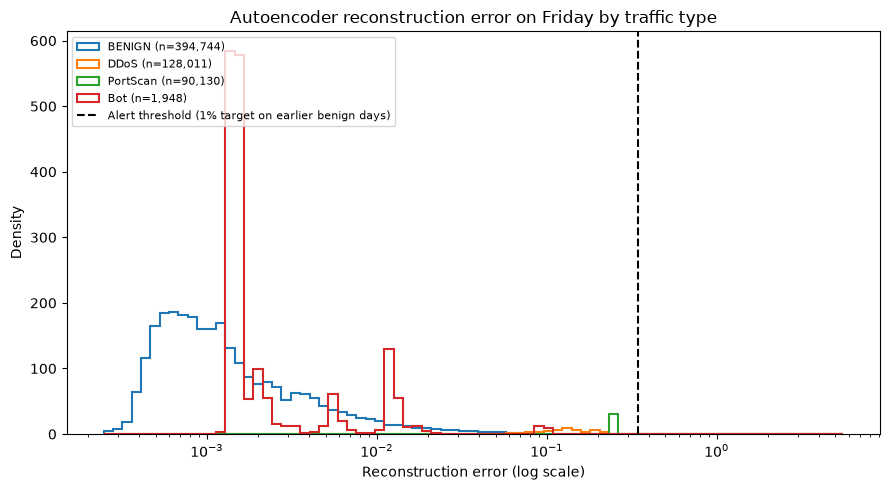

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
fri_labels = pd.Series(labels[te])
bins = np.logspace(np.log10(max(ae_score[te].min(), 1e-6)), np.log10(ae_score[te].max()), 80)
for lab in ["BENIGN", "DDoS", "PortScan", "Bot"]:
    s = ae_score[te][(fri_labels == lab).to_numpy()]
    if len(s):
        ax.hist(s, bins=bins, histtype="step", linewidth=1.5, density=True, label=f"{lab} (n={len(s):,})")
ax.axvline(thresholds["Friday"]["ae"], color="black", linestyle="--", label="Alert threshold (1% target on earlier benign days)")
ax.set_xscale("log")
ax.set_xlabel("Reconstruction error (log scale)"); ax.set_ylabel("Density")
ax.set_title("Autoencoder reconstruction error on Friday by traffic type")
ax.legend(fontsize=8, loc="upper left"); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/05_friday_error_distribution.png", dpi=200); plt.show()

**What this shows** (`05_friday_error_distribution.png`): most benign flows have very small errors, and Bot flows sit in the same range, which is why no model detects Bot. DDoS flows and a concentrated group of PortScan flows have much larger errors, but most of them fall just **below** the alert threshold. So the autoencoder does see these attacks as unusual; the threshold set to keep false alarms near 1% on earlier days is simply too high for them, while Friday's benign tail is heavier than before. The chart is hard to read because the groups differ so much in size; Notebook 06 presents the same scores in a clearer form for the presentation.

## 10. Save the run configuration

In [10]:
config = {
    "notebook": "05_autoencoder",
    "data_fingerprint": fingerprint,
    "target_fpr": TARGET_FPR,
    "preprocessing": "signed log1p, StandardScaler fitted on autoencoder training flows, clip +/-10",
    "autoencoder": {"layers": [len(feature_cols)] + HIDDEN + HIDDEN[-2::-1] + [len(feature_cols)],
                    "activation": "ReLU", "loss": "MSE", "optimiser": "Adam", "learning_rate": LEARNING_RATE,
                    "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
                    "best_epoch": best_epoch, "best_val_loss": best_val, "fit_time_s": round(ae_fit_s, 1),
                    "training_flows": int(len(ae_train_idx)), "early_stopping_flows": int(len(ae_val_idx))},
    "isolation_forest": {**IF_PARAMS, "fit_time_s": round(if_fit_s, 1), "input": "raw features"},
    "thresholds": thresholds,
    "versions": {"python": platform.python_version(), "torch": torch.__version__, "sklearn": sklearn.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__,
                 "matplotlib": matplotlib.__version__},
}
with open(f"{OUT_DIR}/05_run_config.json", "w") as fh:
    json.dump(config, fh, indent=2)
print(json.dumps(config["autoencoder"], indent=2))

{
  "layers": [
    62,
    32,
    16,
    8,
    16,
    32,
    62
  ],
  "activation": "ReLU",
  "loss": "MSE",
  "optimiser": "Adam",
  "learning_rate": 0.001,
  "batch_size": 1024,
  "max_epochs": 50,
  "patience": 3,
  "best_epoch": 49,
  "best_val_loss": 0.02009940752759576,
  "fit_time_s": 13.8,
  "training_flows": 394060,
  "early_stopping_flows": 98516
}


## Summary and questions

1. **Section 4:** the training loss chart. Both lines should fall and flatten; a validation line that rises while training falls would mean over-fitting.
2. **Section 7:** detection and false positive rate per day for the three models. Compare each anomaly detector's false positive rate with the 1% target.
3. **Section 8:** Friday per label against the ceilings, and the "XGBoost or autoencoder" row.

**Summary**
- The autoencoder detected 78.4% of new DoS attacks on Wednesday at a 1.20% false positive rate, where XGBoost detected 0.05%. This is the clearest evidence that the anomaly layer adds value.
- It does not detect brute force, web attacks, Bot or most PortScan flows, which look normal one flow at a time.
- On Friday, normal traffic drifted: the false positive rate reached 6.71% against a 1% target, producing 26,485 false alarms.
- XGBoost and the autoencoder succeed on different days, so they are combined, with triage to manage the alert volume (Notebook 06).

**Questions to be ready for**
- *Why train only on Monday?* It is the only day with no attacks, so the model learns normal traffic only.
- *Why set the threshold at a 1% false positive target instead of the best F1?* Choosing it from attack results would use knowledge a SOC does not have about attacks that have not happened yet. A false-alarm budget is a decision a SOC manager can make in advance.
- *Is a high reconstruction error proof of an attack?* No. It means the flow is unlike Monday's normal traffic. Unusual but legitimate traffic is also flagged, which is why false alarms are reported alongside detections and why Notebook 06 adds priority and explanations for the analyst.
- *Why PyTorch?* The brief does not require it. It was chosen because the explicit training loop makes every step visible and explainable.